# SVD applied to satellite images

This notebook covers the three tasks of the lab:
1. SVD of a satellite image: how many singular values are good enough?
2. Components 10 ... k+10 instead of the k largest: is the image better?
3. Different terrains (forest / urban / ocean): how many singular values are enough?


In [13]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ====== CONFIGURATION: put your own paths here ======
IMAGES = {
    "forest": "images/forest.jpg",
    "urban":  "images/urban.jpg",
    "ocean":  "images/ocean.jpg",
}
MAIN = "urban"     # image used in tasks 1 and 2
MAX_SIDE = 1024    # shrink very large scenes (SVD is slow on huge images); None = keep size


In [14]:
def synthetic(kind, n=512, seed=0):
    """Placeholder images so that the notebook runs without files."""
    rng = np.random.default_rng(seed)
    y, x = np.mgrid[0:n, 0:n] / n
    if kind == "ocean":
        a = 120 + 40*np.sin(6*x + 2*y) + rng.normal(0, 3, (n, n))
    elif kind == "forest":
        a = 100 + rng.normal(0, 25, (n, n))
    else:  # urban: grid of blocks
        blocks = rng.integers(60, 220, (32, 32)).astype(float)
        a = np.kron(blocks, np.ones((n//32, n//32)))
        a[::16, :] = 20; a[:, ::16] = 20
    return np.clip(a, 0, 255)

def load_gray(path, kind=None, max_side=MAX_SIDE):
    """Load an image as a 2D float array (grayscale)."""
    if os.path.exists(path):
        img = Image.open(path).convert("L")
        if max_side and max(img.size) > max_side:
            img.thumbnail((max_side, max_side))
        return np.asarray(img, dtype=float)
    print(f"[!] File {path} not found, using a synthetic image ({kind})")
    return synthetic(kind)

def approx(U, s, Vt, start, end):
    """Reconstruction from components start..end-1 (0-based)."""
    return (U[:, start:end] * s[start:end]) @ Vt[start:end, :]

def psnr(A, B):
    mse = np.mean((A - B)**2)
    return np.inf if mse == 0 else 10*np.log10(255**2 / mse)

def show(ax, M, title):
    ax.imshow(np.clip(M, 0, 255), cmap="gray", vmin=0, vmax=255)  # fixed brightness scale
    ax.set_title(title); ax.axis("off")

def k_for(s, thr_psnr=None, thr_energy=None, shape=None):
    """Smallest k meeting a threshold (computed from singular values, no reconstruction needed)."""
    tot = np.sum(s**2)
    if thr_energy is not None:
        return int(np.searchsorted(np.cumsum(s**2)/tot, thr_energy) + 1)
    err2 = np.maximum(tot - np.cumsum(s**2), 1e-12)      # ||A - A_k||_F^2
    ps = 10*np.log10(255**2 * shape[0]*shape[1] / err2)
    idx = np.where(ps >= thr_psnr)[0]
    return int(idx[0] + 1) if len(idx) else len(s)

def data_fraction(k, shape):
    m, n = shape
    return k*(m + n + 1) / (m*n)    # numbers stored for rank k / numbers in original


## Task 1: SVD of a satellite image. How many singular values are enough?

image size: (634, 1024) | number of singular values: 634
largest singular values: [96285.3  3050.8  2949.1  2674.5  2305.5]


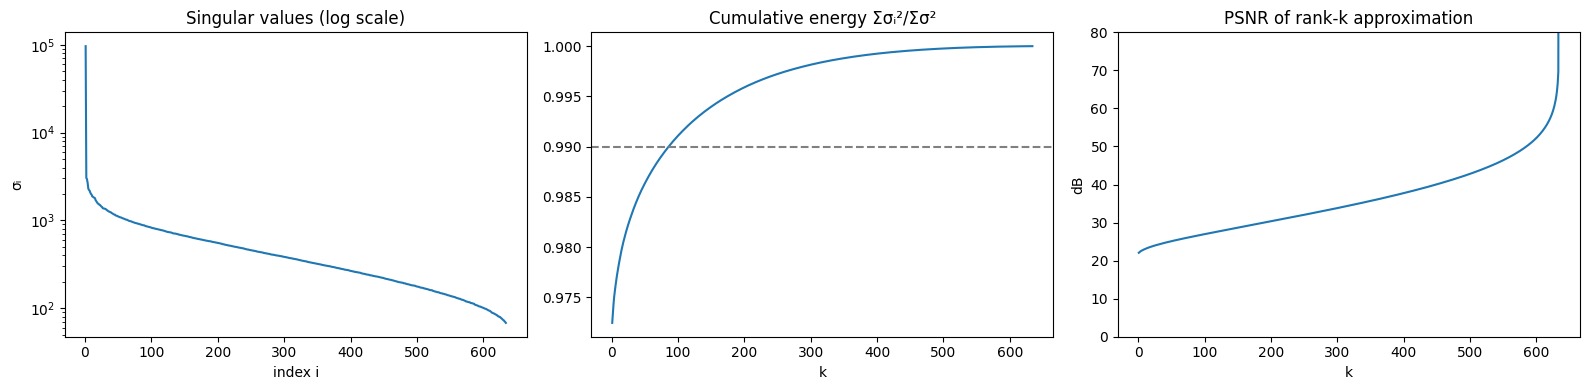


90% of energy: k =    1  (stored data: 0.3% of original)
95% of energy: k =    1  (stored data: 0.3% of original)
99% of energy: k =   86  (stored data: 22.0% of original)
PSNR >= 25 dB: k =   48  (stored data: 12.3% of original)
PSNR >= 30 dB: k =  191  (stored data: 48.8% of original)
PSNR >= 35 dB: k =  333  (stored data: 85.1% of original)
PSNR >= 40 dB: k =  449  (stored data: 114.7% of original)


In [8]:
A = load_gray(IMAGES[MAIN], MAIN)
U, s, Vt = np.linalg.svd(A, full_matrices=False)   # note: Vt is V transposed
m, n = A.shape
print("image size:", A.shape, "| number of singular values:", len(s))
print("largest singular values:", np.round(s[:5], 1))

energy = np.cumsum(s**2) / np.sum(s**2)
err2 = np.maximum(np.sum(s**2) - np.cumsum(s**2), 1e-12)
k_axis = np.arange(1, len(s) + 1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].semilogy(k_axis, s); ax[0].set_title("Singular values (log scale)"); ax[0].set_xlabel("index i"); ax[0].set_ylabel("σᵢ")
ax[1].plot(k_axis, energy); ax[1].axhline(0.99, ls="--", c="gray"); ax[1].set_title("Cumulative energy Σσᵢ²/Σσ²"); ax[1].set_xlabel("k")
ax[2].plot(k_axis, 10*np.log10(255**2 * m*n / err2)); ax[2].set_title("PSNR of rank-k approximation"); ax[2].set_xlabel("k"); ax[2].set_ylabel("dB"); ax[2].set_ylim(0, 80)
plt.tight_layout(); plt.show()

print()
for e in (0.90, 0.95, 0.99):
    k = k_for(s, thr_energy=e)
    print(f"{e:.0%} of energy: k = {k:4d}  (stored data: {data_fraction(k,(m,n)):.1%} of original)")
for p in (25, 30, 35, 40):
    k = k_for(s, thr_psnr=p, shape=(m, n))
    print(f"PSNR >= {p} dB: k = {k:4d}  (stored data: {data_fraction(k,(m,n)):.1%} of original)")


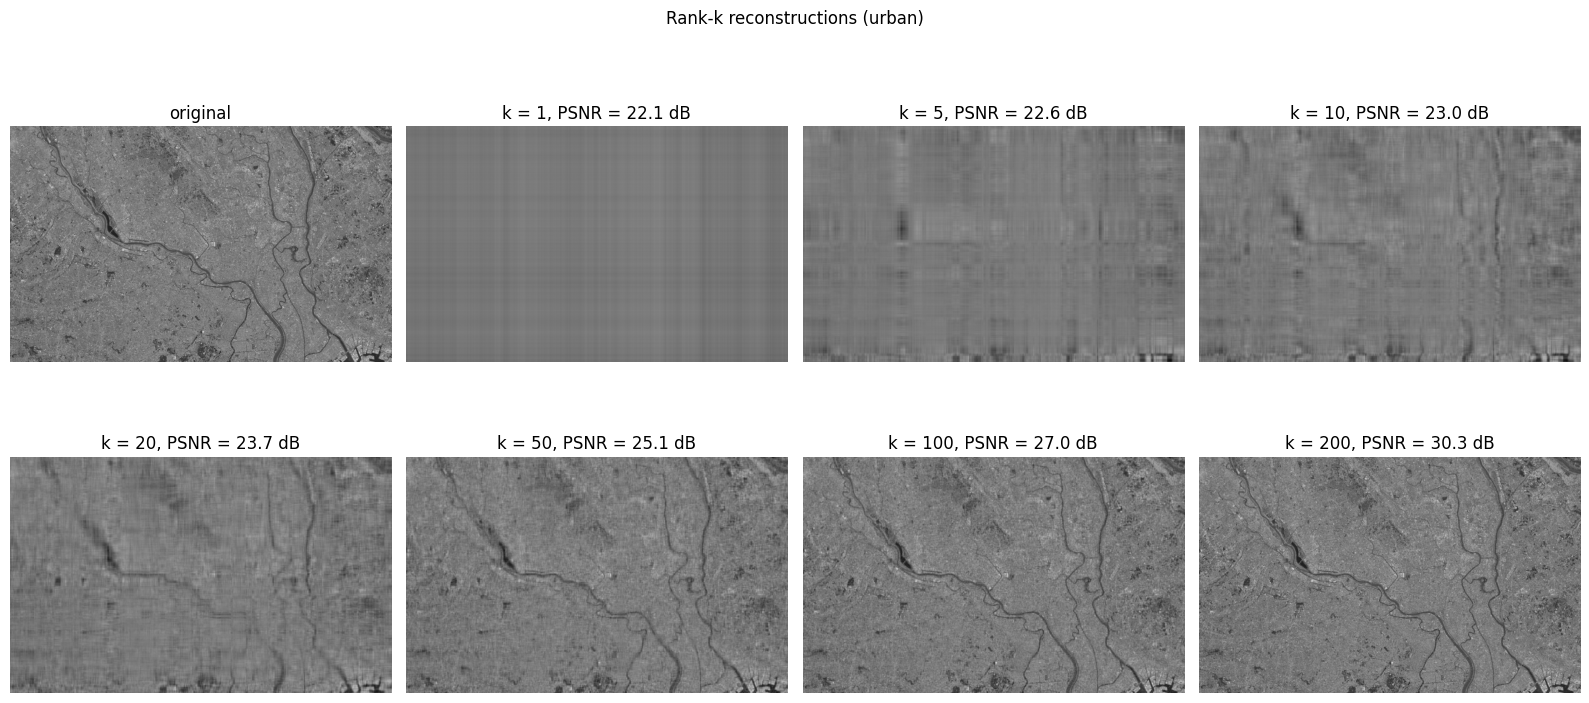

In [9]:
ks = [k for k in [1, 5, 10, 20, 50, 100, 200] if k < len(s)]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
show(axes[0, 0], A, "original")
for ax, k in zip(axes.flat[1:], ks):
    R = approx(U, s, Vt, 0, k)
    show(ax, R, f"k = {k}, PSNR = {psnr(A, R):.1f} dB")
for ax in axes.flat[len(ks) + 1:]: ax.axis("off")
plt.suptitle(f"Rank-k reconstructions ({MAIN})"); plt.tight_layout(); plt.show()


In [10]:
Ac = A - A.mean()
sc = np.linalg.svd(Ac, compute_uv=False)
ec = np.cumsum(sc**2) / np.sum(sc**2)
print("k for 90/95/99% energy (centered):", [int(np.searchsorted(ec, e)) + 1 for e in (0.90, 0.95, 0.99)])

k for 90/95/99% energy (centered): [247, 331, 485]


**Observations:**

**Decay of singular values.** The first singular value is dominant: σ₁ ≈ 96 285, while σ₂ ≈ 3 051, σ₃ ≈ 2 949 and σ₄ ≈ 2 675, so σ₁ is about 30 times larger than σ₂. After the first few values the spectrum falls quickly down to about 10³ and then decreases only slowly and almost linearly on the log scale, from ~10³ at k ≈ 50 to ~10² at k = 634. This heavy tail means that the fine details of the scene (streets, fields, river banks) are spread over a large number of small singular values.

**Energy.** Computed directly on the image matrix, one component already carries more than 97 % of the energy (90 % and 95 % at k = 1, 99 % at k = 86). This is misleading, because σ₁ mostly encodes the mean brightness of the scene, and the k = 1 reconstruction is an almost uniform gray image (PSNR ≈ 22 dB). After subtracting the mean (centering), the energy is spread much more widely: 90 % needs k = 247 (39 % of all 634 singular values), 95 % needs k = 331 (52 %) and 99 % needs k = 485 (76 %). The urban scene therefore contains a lot of fine texture (streets, buildings, fields, river banks) that cannot be captured by a few components. This agrees with the PSNR criterion: about 30 dB requires k = 191 and 35 dB requires k = 333.

**Visual quality vs PSNR.** With k = 5–10 only stripes and blocks are visible, k = 20 gives a blurred image, and at k ≈ 50 (PSNR ≈ 25 dB) the main structures (the river, the city layout) are already recognizable. At k = 100–200 (PSNR ≈ 27–30 dB) the image is very close to the original, with only slightly lower sharpness of fine texture. So visually a decent reconstruction needs about 50–100 components, while the 30–35 dB criterion is stricter and requires k = 191 and k = 333.

**Stored data.** A rank-k approximation requires k·(m+n+1) numbers instead of m·n. For 99 % of the uncentered energy (k = 86) this is 22 % of the original data, for PSNR ≥ 25 dB (k = 48) 12 %, for PSNR ≥ 30 dB (k = 191) 49 %, and for PSNR ≥ 35 dB (k = 333) 85 %. For PSNR ≥ 40 dB (k = 449) it is 115 %, i.e. more than the original image. For the centered energy criteria the storage is about 63 % (k = 247), 85 % (k = 331) and 124 % (k = 485) of the original data. SVD compression stops being profitable at k ≈ 390, and this textured urban scene needs high k for high quality, so SVD is not an efficient compression method for it.

## Task 2: components 10 ... k+10 instead of the k largest

By the Eckart–Young theorem, among all matrices of rank ≤ k the best approximation (in the Frobenius and spectral norm) is the truncation to the k largest singular values. A window 10...k+10 therefore cannot give a smaller error. Let us check it with numbers and visually.

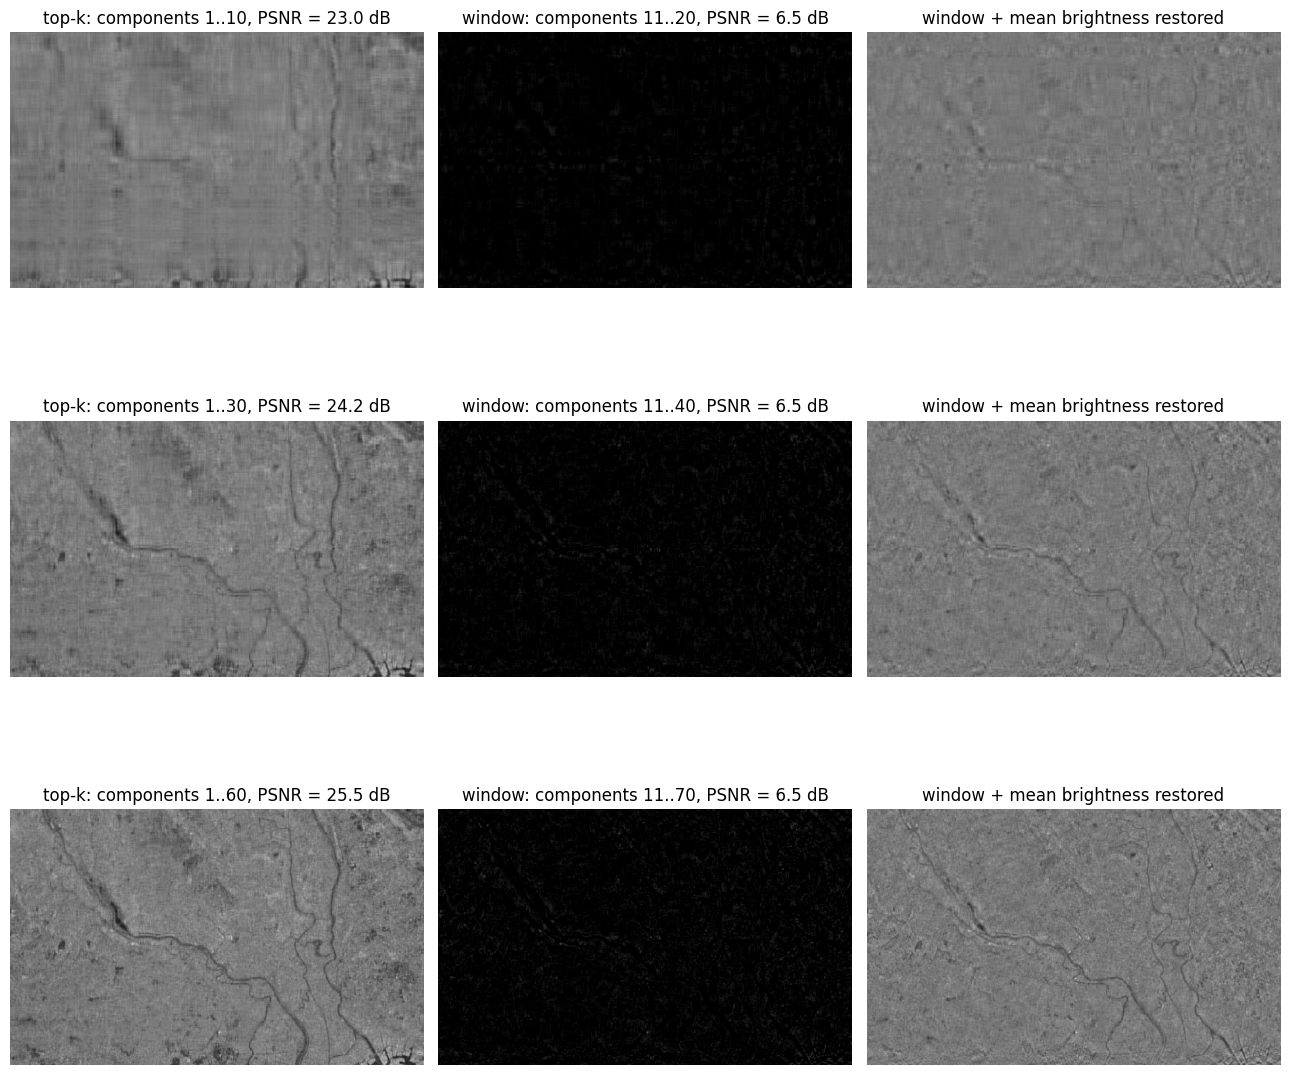

 k | PSNR top-k | PSNR window
 10 |      23.0  |       6.5
 30 |      24.2  |       6.5
 60 |      25.5  |       6.5


In [15]:
ks = [10, 30, 60]
fig, axes = plt.subplots(len(ks), 3, figsize=(13, 4.2*len(ks)))
rows = []
for r, k in enumerate(ks):
    top = approx(U, s, Vt, 0, k)
    win = approx(U, s, Vt, 10, k + 10)
    show(axes[r, 0], top, f"top-k: components 1..{k}, PSNR = {psnr(A, top):.1f} dB")
    show(axes[r, 1], win, f"window: components 11..{k+10}, PSNR = {psnr(A, win):.1f} dB")
    show(axes[r, 2], win + (A.mean() - win.mean()), "window + mean brightness restored")
    rows.append((k, psnr(A, top), psnr(A, win)))
plt.tight_layout(); plt.show()

print(" k | PSNR top-k | PSNR window")
for k, a, b in rows: print(f"{k:3d} | {a:9.1f}  | {b:9.1f}")


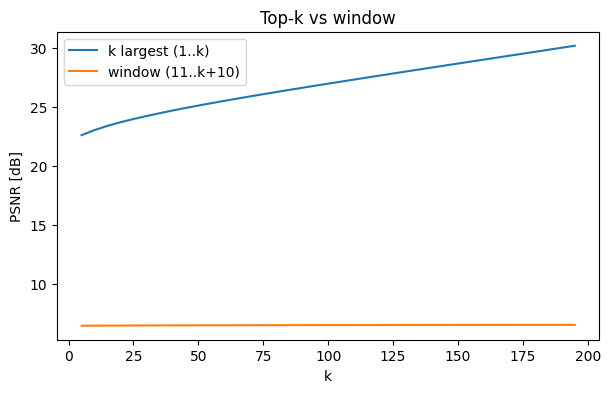

In [ ]:
# PSNR as a function of k for both variants
kk = list(range(5, min(200, len(s) - 10), 5))
p_top = [psnr(A, approx(U, s, Vt, 0, k)) for k in kk]
p_win = [psnr(A, approx(U, s, Vt, 10, k + 10)) for k in kk]
plt.figure(figsize=(7, 4))
plt.plot(kk, p_top, label="k largest (1..k)")
plt.plot(kk, p_win, label="window (11..k+10)")
plt.xlabel("k"); plt.ylabel("PSNR [dB]"); plt.title("Top-k vs window"); plt.legend(); plt.show()


**Observations:**
Is the window better than top‑k? No. For every k the window image (components 11…k+10) is much worse than the top‑k image (components 1…k). The PSNR of top‑k grows from 23.0 dB (k = 10) through 24.2 dB (k = 30) to 25.5 dB (k = 60), and reaches about 30 dB at k ≈ 200, while the PSNR of the window stays practically constant at 6.5 dB, regardless of k. This is what the Eckart–Young theorem predicts: the truncation to the k largest singular values gives the smallest possible error for rank k. The window skips exactly the components that carry most of the energy (above all σ₁, which encodes the mean brightness), so its error is dominated by this missing part, and adding more components after the 10th changes it hardly at all.

What is missing in the window image? The overall brightness level and the large‑scale structure. With the fixed brightness scale (0–255) the window image is almost black, because its values are close to zero (and partly negative, which is clipped on display), and only faint traces of edges (the river, field boundaries) are visible. The first components describe the mean level and the coarse layout of the scene, and without them the image does not resemble the original.

What changes when the mean brightness is restored? The window image becomes visible as a gray picture and the structure of the scene appears: for k = 30 and k = 60 the course of the river, the road network and the field boundaries are clearly visible, and the picture looks like an edge/high‑pass filtered version of the original with sharp contours. For k = 10 (components 11–20) only a weak texture with vertical stripes and a few river segments can be seen. What is still missing are the smooth, large‑scale brightness variations (e.g. darker and brighter areas of the scene), which are carried by components 1–10; the picture therefore looks flatter than the top‑k reconstruction, and its PSNR remains far below that of top‑k.

Where could the window be useful? Omitting the first components works like removing the dominant background: the mean brightness and illumination gradients disappear and local detail remains. This could be useful for emphasizing texture and edges (e.g. rivers, roads, field boundaries in a satellite image), for simple background removal and for detecting small objects on a smooth background. It is not useful for compression or faithful reconstruction, where the largest singular values must be kept.

## Task 3: different terrains (forest / urban / ocean)

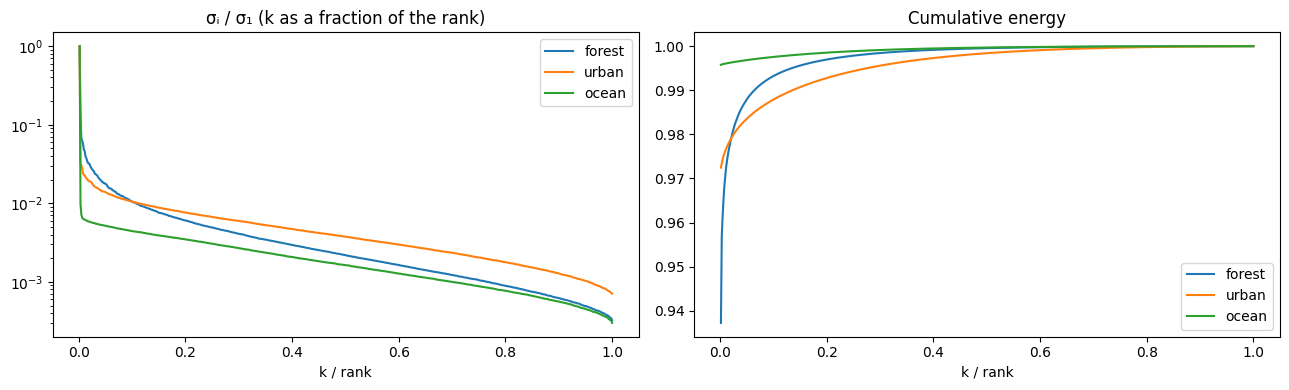

terrain          size  k@95%E  k@99%E  k@30dB  k@35dB  data@35dB
forest    (634, 1024)       2      41      48     136      34.8%
urban     (634, 1024)       1      86     191     333      85.1%
ocean     (634, 1024)       1       1       1      32       8.2%


In [16]:
results = {}
for name, path in IMAGES.items():
    Ai = load_gray(path, name)
    Ui, si, Vti = np.linalg.svd(Ai, full_matrices=False)
    results[name] = dict(A=Ai, U=Ui, s=si, Vt=Vti)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, d in results.items():
    k = np.arange(1, len(d["s"]) + 1) / len(d["s"])     # k as a fraction of the rank, comparable across sizes
    ax[0].semilogy(k, d["s"] / d["s"][0], label=name)
    ax[1].plot(k, np.cumsum(d["s"]**2) / np.sum(d["s"]**2), label=name)
ax[0].set_title("σᵢ / σ₁ (k as a fraction of the rank)"); ax[1].set_title("Cumulative energy")
for a in ax: a.set_xlabel("k / rank"); a.legend()
plt.tight_layout(); plt.show()

print(f"{'terrain':8s} {'size':>12s} {'k@95%E':>7s} {'k@99%E':>7s} {'k@30dB':>7s} {'k@35dB':>7s} {'data@35dB':>10s}")
for name, d in results.items():
    sh = d["A"].shape
    k95 = k_for(d["s"], thr_energy=.95); k99 = k_for(d["s"], thr_energy=.99)
    k30 = k_for(d["s"], thr_psnr=30, shape=sh); k35 = k_for(d["s"], thr_psnr=35, shape=sh)
    print(f"{name:8s} {str(sh):>12s} {k95:7d} {k99:7d} {k30:7d} {k35:7d} {data_fraction(k35, sh):10.1%}")


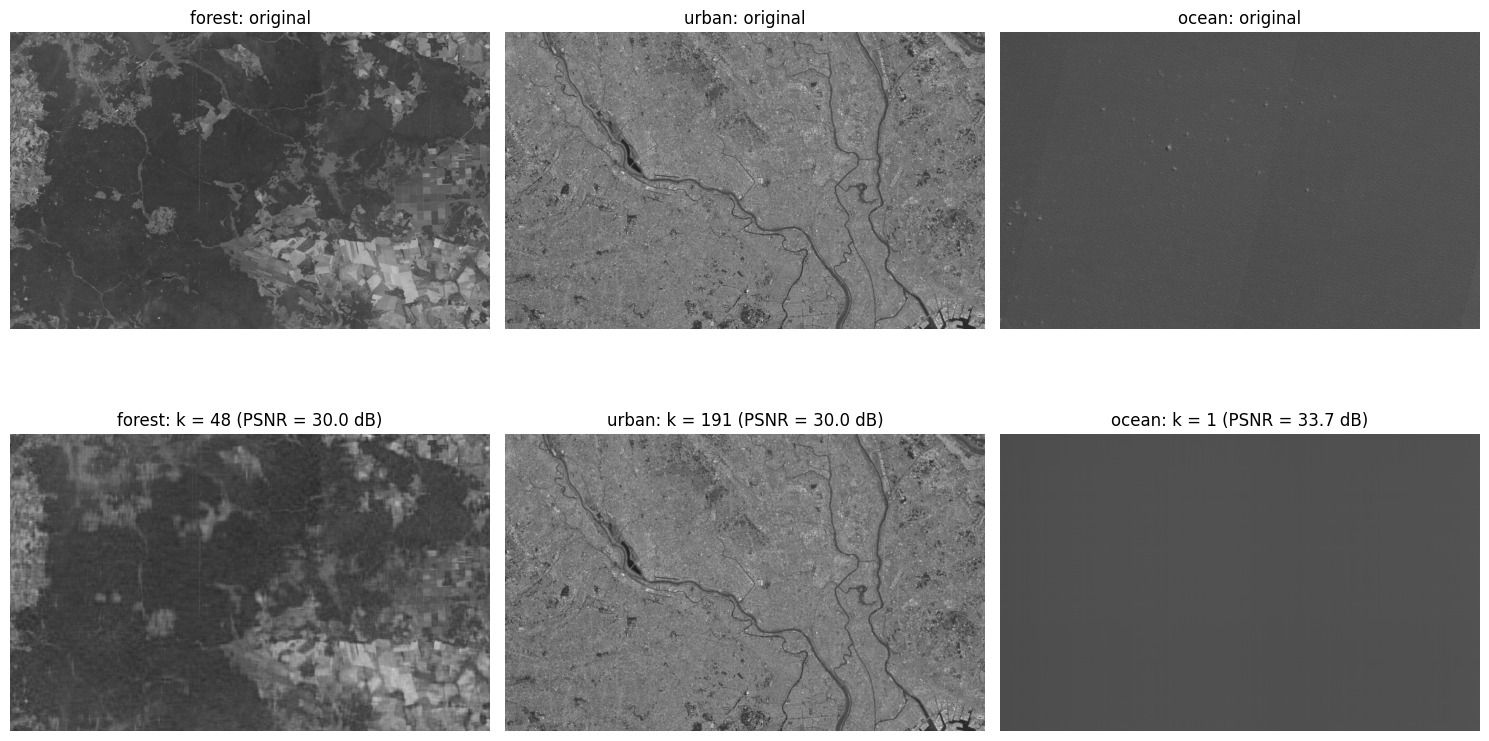

In [17]:
# visual comparison: original vs reconstruction with k giving PSNR ~ 30 dB
fig, axes = plt.subplots(2, len(results), figsize=(5*len(results), 9))
axes = np.atleast_2d(axes).reshape(2, -1)
for c, (name, d) in enumerate(results.items()):
    k = k_for(d["s"], thr_psnr=30, shape=d["A"].shape)
    R = approx(d["U"], d["s"], d["Vt"], 0, k)
    show(axes[0, c], d["A"], f"{name}: original")
    show(axes[1, c], R, f"{name}: k = {k} (PSNR = {psnr(d['A'], R):.1f} dB)")
plt.tight_layout(); plt.show()


In [18]:
from skimage.metrics import structural_similarity as ssim

for name, d in results.items():
    # centered energy
    sc = np.linalg.svd(d["A"] - d["A"].mean(), compute_uv=False)
    ec = np.cumsum(sc**2) / np.sum(sc**2)
    ks = [int(np.searchsorted(ec, e)) + 1 for e in (0.90, 0.95, 0.99)]
    # SSIM at the k giving PSNR ~ 30 dB
    k = k_for(d["s"], thr_psnr=30, shape=d["A"].shape)
    R = np.clip(approx(d["U"], d["s"], d["Vt"], 0, k), 0, 255)
    print(f"{name:7s} centered k@90/95/99% energy: {ks} | SSIM at k={k} (30 dB): {ssim(d['A'], R, data_range=255):.3f}")

forest  centered k@90/95/99% energy: [44, 90, 241] | SSIM at k=48 (30 dB): 0.748
urban   centered k@90/95/99% energy: [247, 331, 485] | SSIM at k=191 (30 dB): 0.848
ocean   centered k@90/95/99% energy: [272, 352, 501] | SSIM at k=1 (30 dB): 0.703


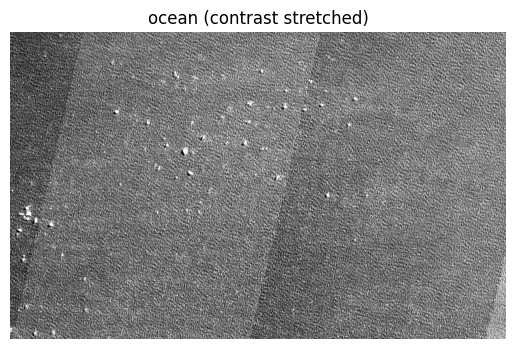

In [19]:
A_o = results["ocean"]["A"]
plt.imshow(A_o, cmap="gray", vmin=np.percentile(A_o, 1), vmax=np.percentile(A_o, 99))
plt.title("ocean (contrast stretched)"); plt.axis("off"); plt.show()

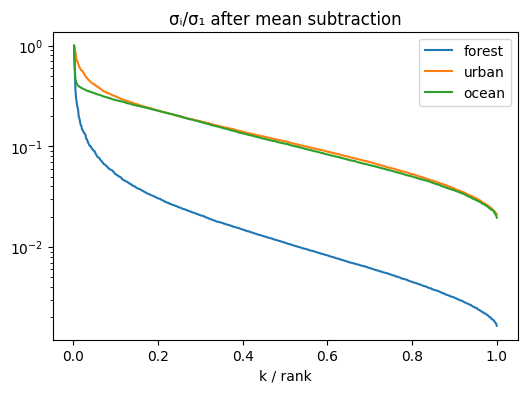

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
for name, d in results.items():
    sc = np.linalg.svd(d["A"] - d["A"].mean(), compute_uv=False)
    ax.semilogy(np.arange(1, len(sc)+1)/len(sc), sc/sc[0], label=name)
ax.set_xlabel("k / rank"); ax.set_title("σᵢ/σ₁ after mean subtraction"); ax.legend(); plt.show()


**Observations**

**Which terrain needs the fewest and which the most singular values?** The answer depends on the criterion. With an absolute error measure (PSNR) the ocean needs the fewest components (k = 1 for 30 dB, k = 32 for 35 dB), then the forest (k = 48 and 136) and the city the most (k = 191 and 333), which corresponds to 8.2 %, 34.8 % and 85.1 % of the original data at 35 dB. With a relative measure, the energy computed after subtracting the mean brightness (centering), the order is different: the forest needs the fewest components (k = 44, 90 and 241 for 90 %, 95 % and 99 % of the energy), then the city (k = 247, 331 and 485), and the ocean the most (k = 272, 352 and 501). For 95 % of the centered energy the storage is about 23 % (forest), 85 % (city) and 90 % (ocean) of the original data. The energy thresholds computed without centering (e.g. k = 1 for 95 % and 99 % in the ocean) are dominated by the mean brightness and are therefore not suitable for comparing terrains.

The reason is the different nature of the three scenes. The forest crop contains large homogeneous regions (dark forest and bright fields with sharp boundaries), so its energy is concentrated in a moderate number of components. The city consists of fine, irregular structures (streets, buildings, river banks) and needs many components for every quality criterion. The ocean is almost uniform: its dominant component is the mean brightness, so a rank-1 approximation is already accurate in absolute terms (PSNR = 33.7 dB). After subtracting the mean, however, what remains is a low-amplitude, noise-like texture. After contrast stretching the ocean image shows a fine granular texture with a few bright point objects (probably ships) and broad bands of slightly different brightness. This texture has no low-rank structure, so its energy is spread over several hundred components. The ocean is therefore "easy" in terms of absolute error and "hard" in terms of relative information content. Part of this texture may come from sensor noise and 8-bit/JPEG quantization of a very low-contrast image, which the contrast stretching amplifies.

The normalized spectra σᵢ/σ₁ computed after subtracting the mean confirm this: the ocean and urban curves almost coincide for k/rank > 0.1, whereas the forest spectrum lies much lower and decays fastest. The first version of this plot (without centering) was misleading for the ocean, because σ₁ there is dominated by the mean brightness.

**Does the "no visible degradation" threshold judged by eye agree with the PSNR threshold?** Only partially. At 30 dB the city (k = 191) is visually almost indistinguishable from the original (SSIM = 0.848), the forest (k = 48) shows visible blurring of the field boundaries (SSIM = 0.748), and the ocean (k = 1) is a uniform gray plane in which the small bright objects of the original have disappeared (SSIM = 0.703). So the same PSNR does not mean the same visual quality: PSNR is dominated by the mean error over all pixels and by the contrast of the scene (a low-contrast ocean image reaches a high PSNR with a trivial reconstruction) and it ignores small local structures. SSIM, which compares local structure, ranks the terrains differently (the ocean reconstruction is the worst despite the highest PSNR) and is closer to what the eye sees.

**Limitations.** The analysis is done in grayscale; for RGB or multispectral satellite images SVD would have to be performed per band. SVD compression is global (each component spans the whole image), so it handles local edges and small objects poorly: they need many components, as seen in the urban scene. This is why image codecs such as JPEG use block-wise DCT instead. The results also depend on the chosen crop and date (the forest crop contains fields, the ocean crop contains ships), on the downscaling to 634 × 1024 px and on the PSNR threshold, which is only an approximation of perception.